# Question 1 — Stage 3: Explore and audit the data (EDA)

**Group number:** 4  
**Student 1:** Niyonsenga Felicien  
**Student 2:** Leonce  
**Question:** Q1 — Maize yield in Rwanda  
**Stage:** 3

This notebook identifies data quality issues before making changes. Run `01_acquire.ipynb` first or ensure the raw CSV exists in `data/raw/`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme()
CWD = Path.cwd()
raw_candidates = [
    CWD / "data" / "raw" / "maize_yield_rwanda_rw.csv",
    CWD / "q1_maize_yield" / "data" / "raw" / "maize_yield_rwanda_rw.csv",
    CWD.parent / "data" / "raw" / "maize_yield_rwanda_rw.csv",
]
RAW_PATH = next((p for p in raw_candidates if p.exists()), None)
if RAW_PATH is None:
    raise FileNotFoundError("Could not find data/raw/maize_yield_rwanda_rw.csv. Open the notebook from the extracted project.")
PROJECT = RAW_PATH.parents[2]
INTERIM = PROJECT / "data" / "interim"
PROCESSED = PROJECT / "data" / "processed"
INTERIM.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(RAW_PATH)

print("Shape:", df.shape)
display(df.head())
display(df.describe(include="all").T)
print("\nMissing values per column:")
display(df.isna().sum().to_frame("missing_count").assign(missing_percent=lambda x: (x.missing_count/len(df)*100).round(2)))
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate record_id values:", df["record_id"].duplicated().sum())

Shape: (1426, 20)


,record_id,year,season,province,district,altitude_m,rainfall_mm,avg_temp_c,soil_ph,soil_type,seed_variety,farming_practice,npk_kg_ha,urea_kg_ha,manure_t_ha,plant_density_per_ha,farm_area_ha,irrigation,pest_incidence_index,yield_t_ha
0,RW-MZ-00001,2015,A,Eastern,Bugesera,1349,NaN,22.9,NaN,Clay,RHM104,Improved,117.8,57.4,1.41,61803,0.63,No,NaN,2.71
1,RW-MZ-00002,2015,A,Eastern,Bugesera,1427,489.8,22.1,6.02,Volcanic,RHM104,Improved,38.1,62.7,3.69,52919,0.17,No,0.339,4.09
2,RW-MZ-00003,2015,A,Northern,Burera,2033,722.6,16.3,5.73,Clay loam,Local,Improved,121.1,50.7,5.18,54406,0.22,No,0.049,2.58
3,RW-MZ-00004,2015,A,Northern,Burera,2026,794.4,16.4,5.20,Clay loam,ZM621,Improved,93.7,60.4,1.68,48119,0.48,No,0.171,2.45
4,RW-MZ-00005,2015,A,Northern,Gakenke,1974,644.2,18.3,5.92,Loam,Local,Improved,84.1,70.4,0.36,56787,1.16,No,0.001,2.09


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
record_id,1426,1426,RW-MZ-00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,1426.0,NaN,NaN,NaN,2019.506311,2.855643,2015.0,2017.0,2020.0,2022.0,2024.0
season,1426,3,A,600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
province,1426,5,Southern,388,NaN,NaN,NaN,NaN,NaN,NaN,NaN
district,1426,30,Karongi,56,NaN,NaN,NaN,NaN,NaN,NaN,NaN
altitude_m,1426.0,NaN,NaN,NaN,1704.321879,221.267632,1243.0,1507.0,1702.5,1879.75,2341.0
rainfall_mm,1415.0,NaN,NaN,NaN,516.165371,155.676106,150.0,419.35,530.6,627.45,933.3
avg_temp_c,1426.0,NaN,NaN,NaN,19.404137,1.645486,15.4,18.025,19.4,20.7,23.0
soil_ph,1412.0,NaN,NaN,NaN,5.835156,0.443019,4.5,5.53,5.84,6.13,7.2
soil_type,1426,5,Loam,410,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values per column:


,missing_count,missing_percent
record_id,0,0.00
year,0,0.00
season,0,0.00
province,0,0.00
district,0,0.00
altitude_m,0,0.00
rainfall_mm,11,0.77
avg_temp_c,0,0.00
soil_ph,14,0.98
soil_type,0,0.00


Exact duplicate rows: 0
Duplicate record_id values: 0


## Unique categorical values

In [2]:
cat_cols = df.select_dtypes(include="object").columns.tolist()
for col in cat_cols:
    print(f"\n{col}: {sorted(df[col].dropna().astype(str).unique().tolist())}")


record_id: ['RW-MZ-00001', 'RW-MZ-00002', 'RW-MZ-00003', 'RW-MZ-00004', 'RW-MZ-00005', 'RW-MZ-00006', 'RW-MZ-00007', 'RW-MZ-00008', 'RW-MZ-00009', 'RW-MZ-00010', 'RW-MZ-00011', 'RW-MZ-00012', 'RW-MZ-00013', 'RW-MZ-00014', 'RW-MZ-00015', 'RW-MZ-00016', 'RW-MZ-00017', 'RW-MZ-00018', 'RW-MZ-00019', 'RW-MZ-00020', 'RW-MZ-00021', 'RW-MZ-00022', 'RW-MZ-00023', 'RW-MZ-00024', 'RW-MZ-00025', 'RW-MZ-00026', 'RW-MZ-00027', 'RW-MZ-00028', 'RW-MZ-00029', 'RW-MZ-00030', 'RW-MZ-00031', 'RW-MZ-00032', 'RW-MZ-00033', 'RW-MZ-00034', 'RW-MZ-00035', 'RW-MZ-00036', 'RW-MZ-00037', 'RW-MZ-00038', 'RW-MZ-00039', 'RW-MZ-00040', 'RW-MZ-00041', 'RW-MZ-00042', 'RW-MZ-00043', 'RW-MZ-00044', 'RW-MZ-00045', 'RW-MZ-00046', 'RW-MZ-00047', 'RW-MZ-00048', 'RW-MZ-00049', 'RW-MZ-00050', 'RW-MZ-00051', 'RW-MZ-00052', 'RW-MZ-00053', 'RW-MZ-00054', 'RW-MZ-00055', 'RW-MZ-00056', 'RW-MZ-00057', 'RW-MZ-00058', 'RW-MZ-00059', 'RW-MZ-00060', 'RW-MZ-00061', 'RW-MZ-00062', 'RW-MZ-00063', 'RW-MZ-00064', 'RW-MZ-00065', 'RW-MZ-00066

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_15224\3829418140.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.tolist()


## Check impossible or suspicious values
Use domain checks as flags, not automatic deletion rules. An unusual value should be investigated and documented.

In [3]:
checks = {
    "year_outside_2015_2024": ~df["year"].between(2015, 2024),
    "negative_altitude": df["altitude_m"] < 0,
    "negative_rainfall": df["rainfall_mm"] < 0,
    "temperature_outside_10_35C": ~df["avg_temp_c"].between(10, 35),
    "soil_ph_outside_4_8": ~df["soil_ph"].between(4, 8),
    "negative_fertiliser": (df[["npk_kg_ha","urea_kg_ha","manure_t_ha"]] < 0).any(axis=1),
    "nonpositive_farm_area": df["farm_area_ha"] <= 0,
    "nonpositive_yield": df["yield_t_ha"] <= 0,
    "pest_index_outside_0_1": ~df["pest_incidence_index"].between(0, 1),
}
quality_flags = pd.DataFrame({k: v.fillna(False) for k,v in checks.items()})
display(quality_flags.sum().to_frame("records_flagged"))

,records_flagged
year_outside_2015_2024,0
negative_altitude,0
negative_rainfall,0
temperature_outside_10_35C,0
soil_ph_outside_4_8,14
negative_fertiliser,0
nonpositive_farm_area,0
nonpositive_yield,0
pest_index_outside_0_1,14


## Outlier screening with IQR
The IQR method identifies statistical extremes; it does not prove that values are errors. Keep plausible extremes unless the source or domain review shows they are invalid.

In [4]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
outlier_rows=[]
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25,0.75])
    iqr=q3-q1
    low, high=q1-1.5*iqr, q3+1.5*iqr
    count=((df[col]<low)|(df[col]>high)).sum()
    outlier_rows.append((col, low, high, int(count)))
outlier_report=pd.DataFrame(outlier_rows, columns=["column","IQR_lower_bound","IQR_upper_bound","outlier_count"])
display(outlier_report)

,column,IQR_lower_bound,IQR_upper_bound,outlier_count
0,year,2009.500000,2029.500000,0
1,altitude_m,947.875000,2438.875000,0
2,rainfall_mm,107.200000,939.600000,0
3,avg_temp_c,14.012500,24.712500,0
4,soil_ph,4.630000,7.030000,10
5,npk_kg_ha,-91.712500,222.987500,0
6,urea_kg_ha,-64.062500,137.437500,0
7,manure_t_ha,-1.891250,5.978750,6
8,plant_density_per_ha,15469.375000,76808.375000,0
9,farm_area_ha,-0.320000,1.760000,75


## Required visual analysis — at least five charts

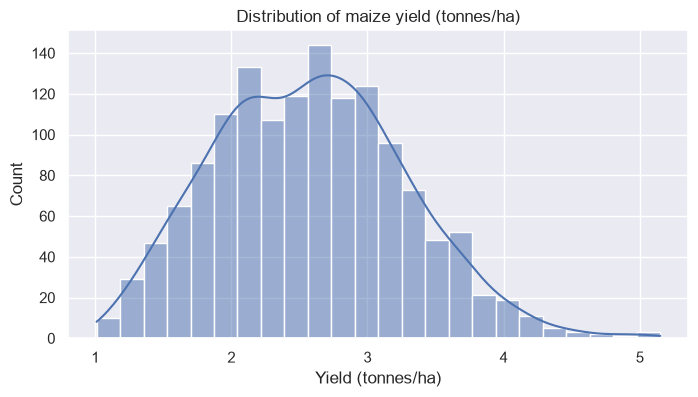

Interpretation: The histogram shows the distribution and spread of the target yield. Check for skewness and unusual tails.


In [5]:
# 1. Target distribution
plt.figure(figsize=(8,4))
sns.histplot(df["yield_t_ha"], kde=True)
plt.title("Distribution of maize yield (tonnes/ha)")
plt.xlabel("Yield (tonnes/ha)")
plt.show()
print("Interpretation: The histogram shows the distribution and spread of the target yield. Check for skewness and unusual tails.")

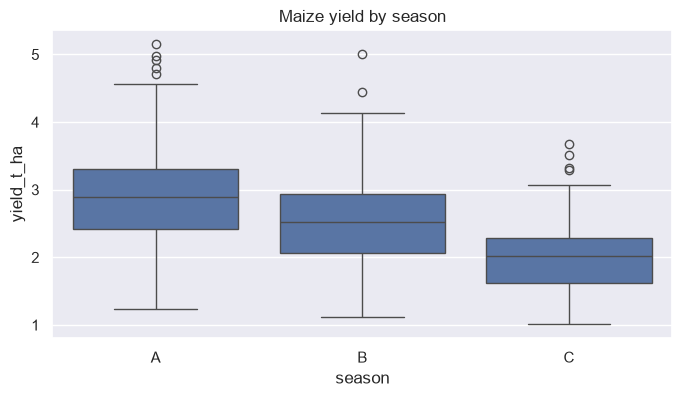

Interpretation: Compare the median and spread of yield across seasons A, B and C.


In [6]:
# 2. Yield by season
plt.figure(figsize=(8,4))
sns.boxplot(data=df, x="season", y="yield_t_ha")
plt.title("Maize yield by season")
plt.show()
print("Interpretation: Compare the median and spread of yield across seasons A, B and C.")

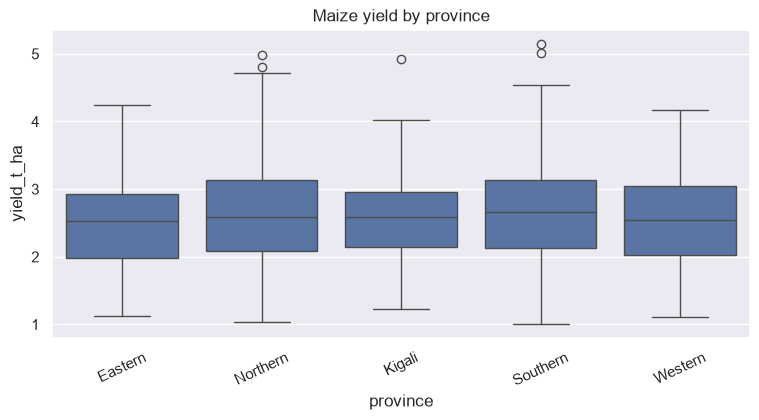

Interpretation: Differences between provincial distributions may indicate geographic or climate-related variation.


In [7]:
# 3. Yield by province
plt.figure(figsize=(9,4))
sns.boxplot(data=df, x="province", y="yield_t_ha")
plt.title("Maize yield by province")
plt.xticks(rotation=25)
plt.show()
print("Interpretation: Differences between provincial distributions may indicate geographic or climate-related variation.")

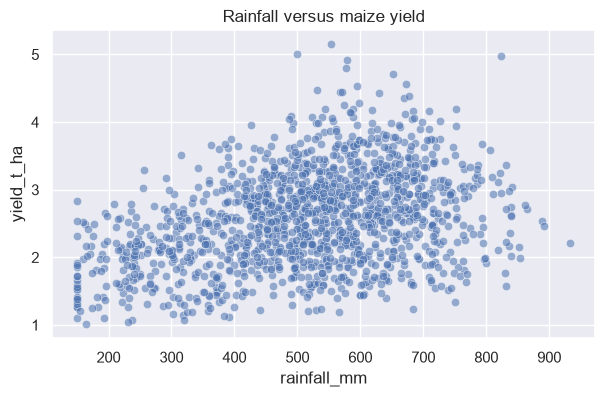

Interpretation: The scatter plot helps assess whether rainfall has an apparent association with yield; association is not proof of causation.


In [8]:
# 4. Rainfall and yield
plt.figure(figsize=(7,4))
sns.scatterplot(data=df, x="rainfall_mm", y="yield_t_ha", alpha=.55)
plt.title("Rainfall versus maize yield")
plt.show()
print("Interpretation: The scatter plot helps assess whether rainfall has an apparent association with yield; association is not proof of causation.")

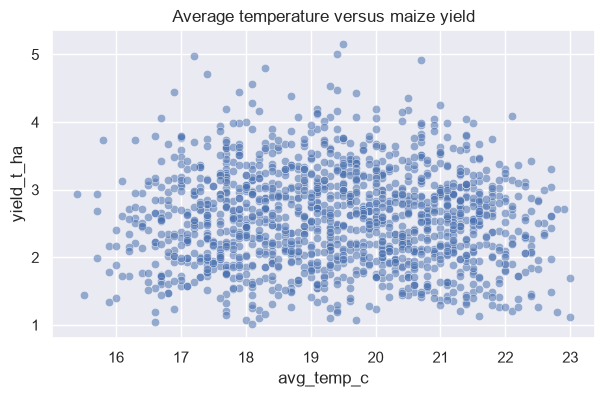

Interpretation: Inspect whether yield changes across the observed temperature range.


In [9]:
# 5. Temperature and yield
plt.figure(figsize=(7,4))
sns.scatterplot(data=df, x="avg_temp_c", y="yield_t_ha", alpha=.55)
plt.title("Average temperature versus maize yield")
plt.show()
print("Interpretation: Inspect whether yield changes across the observed temperature range.")

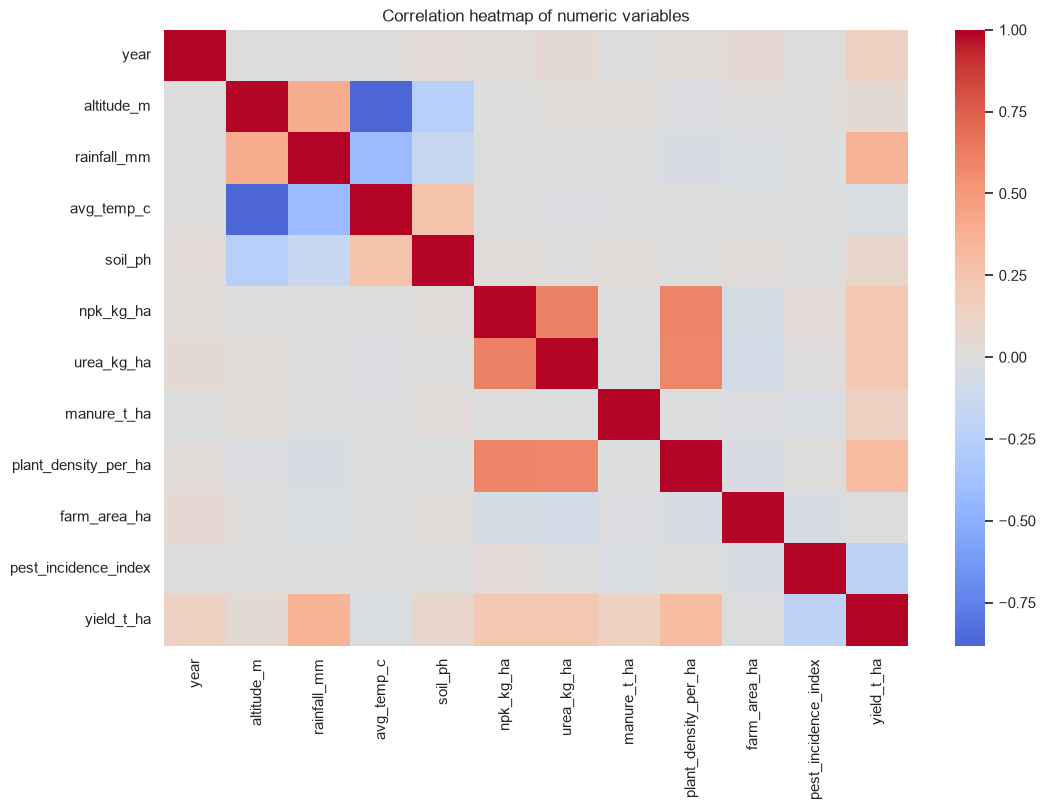

Interpretation: Correlations show linear associations among numeric columns. They do not establish causal effects.


In [10]:
# 6. Numeric correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(df.select_dtypes(include=np.number).corr(), cmap="coolwarm", center=0)
plt.title("Correlation heatmap of numeric variables")
plt.show()
print("Interpretation: Correlations show linear associations among numeric columns. They do not establish causal effects.")

## Data Quality Report — preliminary, generated from this CSV
The table below captures detected issues. Add any spelling, unit, provenance or domain issues found during manual review. Severity is a judgement that your group must defend.

In [11]:
missing = df.isna().sum()
quality_report = pd.DataFrame([
    ("Missing rainfall values","rainfall_mm",int(missing["rainfall_mm"]),"Medium","Impute using training-set median; preserve raw file."),
    ("Missing soil pH values","soil_ph",int(missing["soil_ph"]),"Medium","Impute using training-set median; record limitation."),
    ("Missing pest index values","pest_incidence_index",int(missing["pest_incidence_index"]),"Medium","Impute using training-set median; record limitation."),
    ("Exact duplicate rows","All columns",int(df.duplicated().sum()),"Low","Remove only if duplicates are found."),
    ("Duplicate record IDs","record_id",int(df["record_id"].duplicated().sum()),"High","Investigate and resolve if any occur."),
    ("Identifier column","record_id",int(df["record_id"].notna().sum()),"Low","Exclude from model predictors; retain for traceability."),
    ("Target column is post-harvest","yield_t_ha",len(df),"High","Keep as target only; never include as an input feature."),
], columns=["problem","affected_column","records_affected","severity","proposed_treatment"])
display(quality_report)
quality_report.to_csv(PROJECT/"docs"/"data_quality_report.csv", index=False)

,problem,affected_column,records_affected,severity,proposed_treatment
0,Missing rainfall values,rainfall_mm,11,Medium,Impute using training-set median; preserve raw...
1,Missing soil pH values,soil_ph,14,Medium,Impute using training-set median; record limit...
2,Missing pest index values,pest_incidence_index,14,Medium,Impute using training-set median; record limit...
3,Exact duplicate rows,All columns,0,Low,Remove only if duplicates are found.
4,Duplicate record IDs,record_id,0,High,Investigate and resolve if any occur.
5,Identifier column,record_id,1426,Low,Exclude from model predictors; retain for trac...
6,Target column is post-harvest,yield_t_ha,1426,High,Keep as target only; never include as an input...
